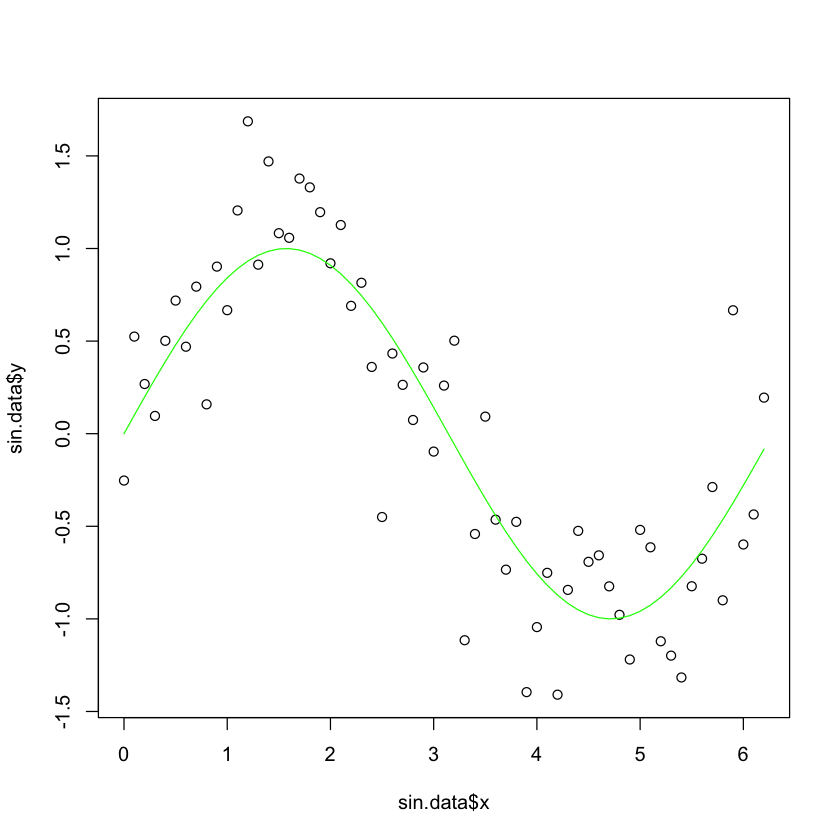

In [5]:
# Set default graphics parameters
set_plot_defaults <- function() {
    par(bg="white",
        col="black",
        col.axis="black",
        col.lab="black",
        col.main="black",
        col.sub="black",
        fg="black")
}
set_plot_defaults()




x <- seq(0, pi * 2, 0.1)
#y <- sin(x)
y <- sin(x) + rnorm(n = length(x), mean = 0, sd = sd(sin(x) / 2))
sin.data <- data.frame(y,x)
plot(sin.data$x,sin.data$y)
lines(sin.data$x,sin(sin.data$x),col="green")



In [3]:
lm.sin <- lm(y ~ x, data = sin.data) # learn the linear model
lm.sin.pred <- predict(lm.sin, interval="confidence") # make predictions at testing points
summary(lm.sin) # the model works somehow, explains more than 40% of the variance, much better than averaging


Call:
lm(formula = y ~ x, data = sin.data)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.27561 -0.43113  0.03406  0.45368  1.16889 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.91260    0.14676   6.218 5.00e-08 ***
x           -0.29309    0.04083  -7.178 1.15e-09 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.5894 on 61 degrees of freedom
Multiple R-squared:  0.4579,	Adjusted R-squared:  0.449 
F-statistic: 51.52 on 1 and 61 DF,  p-value: 1.147e-09


In [7]:
myRMSE <- function(predicted, actual) {
  sqrt(mean((predicted - actual)^2))
}

In [ ]:
myRMSE(predict(lm.sin,sin.data),sin.data$y) # RMSE on train data
myRMSE(0,sin.data$y) # RMSE of the zero model on train data


[1] 0.6014208

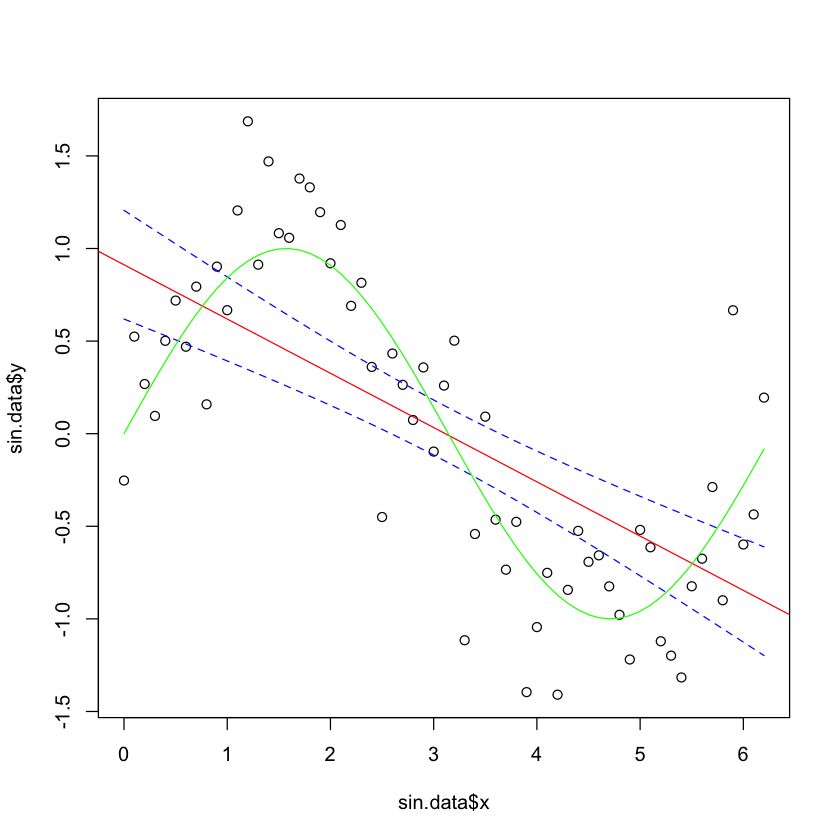

In [9]:
set_plot_defaults()

plot(sin.data$x,sin.data$y)
abline(lm.sin,col="red")

lines(sin.data$x,lm.sin.pred[,"lwr"],col="blue",lty=2)
lines(sin.data$x,lm.sin.pred[,"upr"],col="blue",lty=2)
lines(sin.data$x,sin(sin.data$x),col="green")

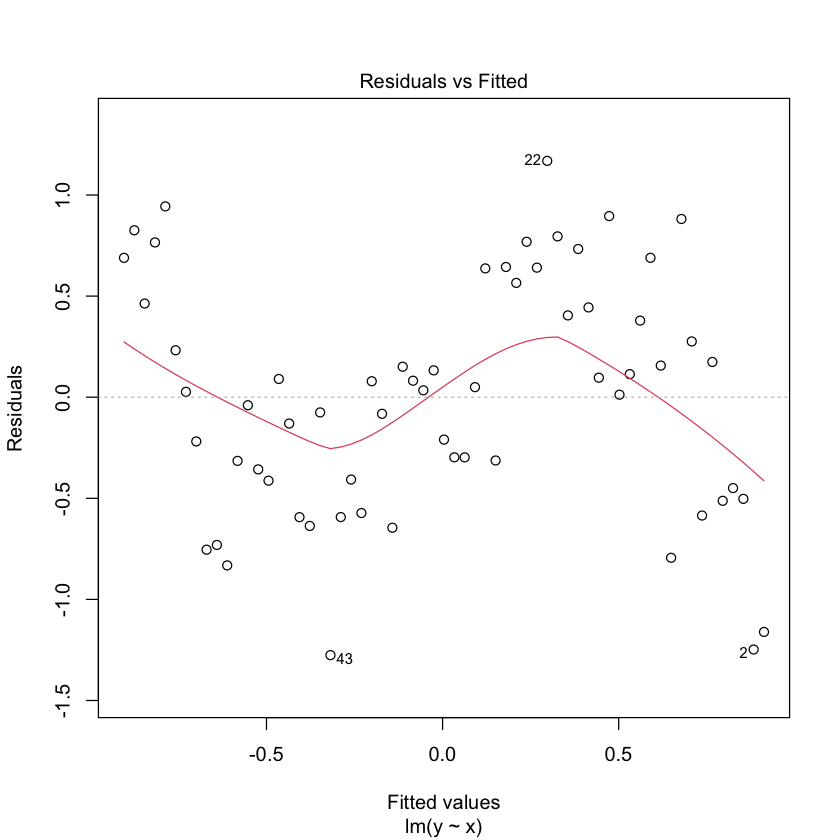

In [11]:

set_plot_defaults()
plot(lm.sin,which=1) # however, the assumptions violated, unreliable confidence intervals, the model underfits the data


In [14]:
sin.test <- data.frame(x=seq(0, pi * 2, 0.1),y=sin(x) + rnorm(n = length(x), mean = 0, sd = sd(sin(x) / 2)))
myRMSE(predict(lm.sin,sin.test),sin.test$y) # RMSE on test data
myRMSE(0,sin.test$y) # RMSE of the zero model on test data
lm.sin.cub <- lm(y ~ poly(x,3), data = sin.data) # learn the linear model
lm.sin.pred <- predict(lm.sin.cub, interval="confidence") # make predictions at testing points
summary(lm.sin.cub) # the model works even better, explains nearly 80% of the variance, much better than linear model

[1] 0.589006

[1] 0.7555377


Call:
lm(formula = y ~ poly(x, 3), data = sin.data)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.96744 -0.21845  0.01455  0.27386  1.00345 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.003416   0.048232   0.071    0.944    
poly(x, 3)1 -4.572270   0.382831 -11.943  < 2e-16 ***
poly(x, 3)2  0.090579   0.382831   0.237    0.814    
poly(x, 3)3  3.743706   0.382831   9.779  5.9e-14 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.3828 on 59 degrees of freedom
Multiple R-squared:  0.8016,	Adjusted R-squared:  0.7915 
F-statistic: 79.44 on 3 and 59 DF,  p-value: < 2.2e-16


In [15]:
myRMSE(predict(lm.sin.cub,sin.data),sin.data$y) # RMSE on train data
myRMSE(predict(lm.sin.cub,sin.test),sin.test$y) # RMSE on test data

[1] 0.3704781

[1] 0.3624674

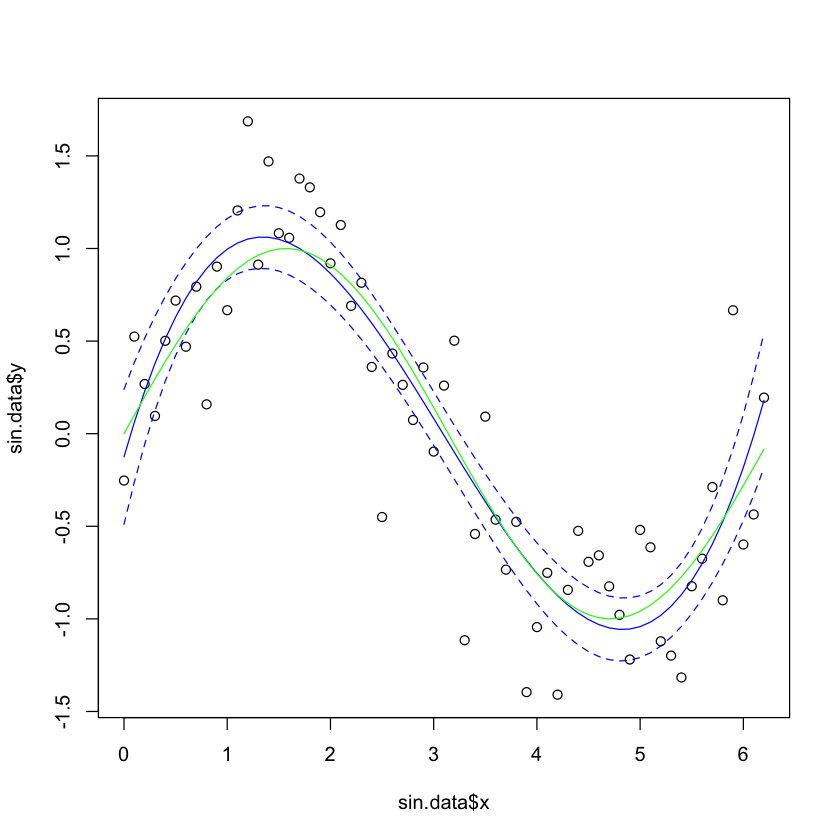

In [18]:
set_plot_defaults()

plot(sin.data$x,sin.data$y)

lines(sin.data$x,lm.sin.pred[,"fit"],col="blue")
lines(sin.data$x,lm.sin.pred[,"lwr"],col="blue",lty=2)
lines(sin.data$x,lm.sin.pred[,"upr"],col="blue",lty=2)
lines(sin.data$x,sin(sin.data$x),col="green")